# Industry Project: Explaining Loan Decisions with SHAP (Production-Style)

> **Who is this notebook for?** Beginners who want to see how companies explain machine-learning decisions to **managers, customers and regulators**.
> Every step is explained in plain English and the code is heavily commented.

---

### How this notebook is different from `01_explainability.ipynb`

| `01_explainability.ipynb` | This notebook |
|---|---|
| What SHAP, LIME, PDP, ICE are | How a bank **uses** them in a real decision process |
| Generic plots | **Customer-facing reason codes**, sanity checks, a **model card** |

### The business problem
A lender uses a model to approve or decline loan applications. By law in many countries (e.g. the US *Equal Credit Opportunity Act*, the EU AI Act, GDPR's "right to explanation"), a declined applicant must receive **the main reasons** for the decision.

**Your job:**
1. Train an accurate model **with built-in business logic** (monotonic constraints).
2. Explain the model **globally** (to managers and risk teams).
3. Explain **individual decisions** (to customers): "Declined because: high debt-to-income ratio, ...".
4. Write a short **model card** documenting the model.

### Table of Contents
1. Setup
2. Loan application data
3. Train a model with monotonic constraints
4. Global explanations: what drives the model overall?
5. Does the model behave sensibly? (dependence plots)
6. Local explanations: why was *this* applicant declined?
7. Turning SHAP into customer reason codes
8. Fairness spot-check
9. Model card
10. Summary

---
## 1. Setup
**SHAP** (SHapley Additive exPlanations) is the industry standard for explaining tree models. For each prediction, it splits the model's output into **contributions per feature** that add up exactly to the prediction.

In [1]:
import warnings

import lightgbm as lgb                     # fast gradient boosting, very common in industry
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap                                # explanations
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
APPROVAL_THRESHOLD = 0.15                  # decline if predicted default risk is above 15%
print("shap", shap.__version__, "| lightgbm", lgb.__version__)

shap 0.47.2 | lightgbm 4.6.0


/path/to/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## 2. Loan application data
We simulate 10,000 past applications with their outcome: did the borrower **default** (fail to repay)?
`age_group` is stored for **fairness auditing only**: it is **not** used as a model input (using protected attributes for credit decisions is illegal in many places).

In [2]:
def simulate_applications(n: int = 10_000, seed: int = RANDOM_STATE) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "annual_income": rng.lognormal(10.9, 0.45, n).round(-2),            # ~ $55k median
        "loan_amount": rng.lognormal(9.6, 0.6, n).round(-2),                # ~ $15k median
        "credit_score": rng.normal(680, 60, n).clip(300, 850).round(),
        "years_employed": rng.exponential(5, n).clip(0, 40).round(1),
        "num_late_payments_2y": rng.poisson(0.6, n),
        "existing_debt": rng.lognormal(9.0, 1.0, n).round(-2),
        "home_owner": rng.choice([0, 1], n, p=[0.6, 0.4]),
        "age_group": rng.choice(["18-30", "31-50", "51+"], n, p=[0.3, 0.45, 0.25]),
    })
    df["debt_to_income"] = ((df["existing_debt"] + df["loan_amount"]) / df["annual_income"]).round(3)
    logit = (-2.2 - 0.012 * (df["credit_score"] - 680) + 1.6 * (df["debt_to_income"] - 0.6)
             + 0.45 * df["num_late_payments_2y"] - 0.05 * df["years_employed"] - 0.3 * df["home_owner"])
    df["defaulted"] = rng.binomial(1, 1 / (1 + np.exp(-logit)))
    return df


apps = simulate_applications()
FEATURES = ["annual_income", "loan_amount", "credit_score", "years_employed",
            "num_late_payments_2y", "existing_debt", "home_owner", "debt_to_income"]
print(f"{len(apps):,} applications | default rate {apps['defaulted'].mean():.1%}")
apps.head()

10,000 applications | default rate 14.0%


,annual_income,loan_amount,credit_score,years_employed,num_late_payments_2y,existing_debt,home_owner,age_group,debt_to_income,defaulted
0,62100.0,16400.0,581.0,11.6,2,11200.0,1,18-30,0.444,0
1,33900.0,25300.0,733.0,6.8,0,4200.0,1,18-30,0.870,0
2,75900.0,6100.0,677.0,1.9,2,8300.0,0,18-30,0.190,1
3,82700.0,12400.0,644.0,1.3,3,25400.0,1,31-50,0.457,0
4,22500.0,24300.0,665.0,1.0,1,15700.0,1,18-30,1.778,0


---
## 3. Train a model with monotonic constraints

A powerful model might learn weird things from noise, like "credit score 702 is riskier than 701". Customers and regulators would never accept that.
**Monotonic constraints** force the model to respect business logic:

| Feature | Constraint | Meaning |
|---|---|---|
| `credit_score` | −1 | higher score → risk can only go **down** |
| `num_late_payments_2y`, `debt_to_income` | +1 | more → risk can only go **up** |
| others | 0 | no constraint |

This is one of the most common "industry tricks" for regulated models (see `02_interpretable_models.ipynb`).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    apps[FEATURES], apps["defaulted"], test_size=0.25, stratify=apps["defaulted"], random_state=RANDOM_STATE)
age_test = apps.loc[X_test.index, "age_group"]          # kept aside for the fairness check

MONOTONE = {"credit_score": -1, "num_late_payments_2y": 1, "debt_to_income": 1, "years_employed": -1}
constraints = [MONOTONE.get(f, 0) for f in FEATURES]   # same order as the columns

model = lgb.LGBMClassifier(
    n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
    monotone_constraints=constraints, random_state=RANDOM_STATE, verbose=-1)
model.fit(X_train, y_train)

risk_test = model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, risk_test):.3f}")
print(f"Approval rate at {APPROVAL_THRESHOLD:.0%} risk threshold: {(risk_test < APPROVAL_THRESHOLD).mean():.1%}")

Test ROC-AUC: 0.790
Approval rate at 15% risk threshold: 70.9%


---
## 4. Global explanations: what drives the model overall?

We compute SHAP values for the test applicants. Two standard plots:
- **Bar plot**: average impact of each feature, the "importance ranking" for managers.
- **Beeswarm plot**: every dot is one applicant. Colour = feature value (red high, blue low). Position = push towards higher (right) or lower (left) default risk.

SHAP values here are in **log-odds** units (the model's internal score). Positive = more risk.

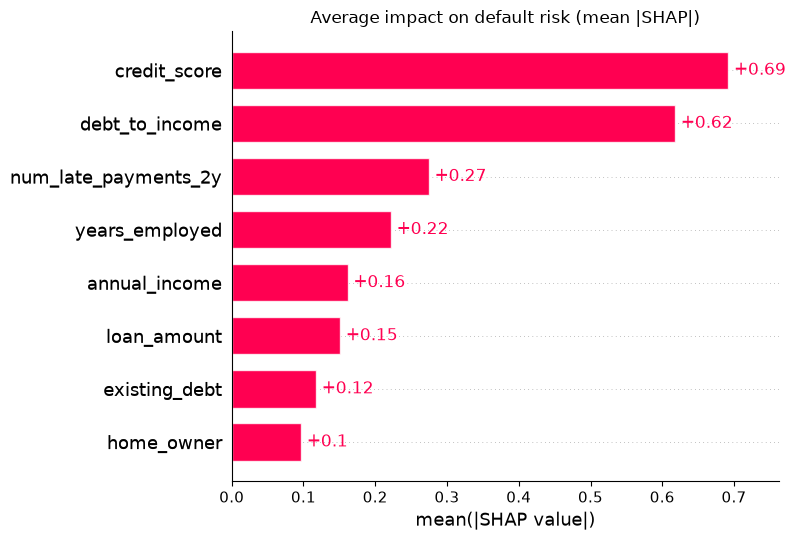

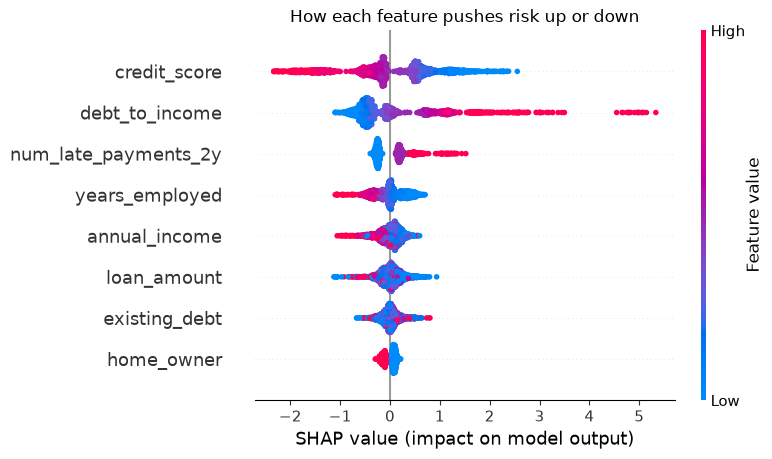

In [4]:
explainer = shap.TreeExplainer(model)              # fast, exact SHAP for tree models
shap_values = explainer(X_test)                    # an Explanation object: values + data + base value

shap.plots.bar(shap_values, show=False)
plt.title("Average impact on default risk (mean |SHAP|)"); plt.tight_layout(); plt.show()

shap.plots.beeswarm(shap_values, show=False)
plt.title("How each feature pushes risk up or down"); plt.tight_layout(); plt.show()

**How to read the beeswarm:** for `credit_score`, red dots (high scores) sit on the **left** (lower risk) and blue dots (low scores) on the right. That's exactly what a credit expert expects. If it were the other way round, **stop and investigate**: it would indicate a data bug or leakage.

---
## 5. Does the model behave sensibly? (dependence plots)
A dependence plot shows how the SHAP value of one feature changes with its value. Thanks to monotonic constraints, these curves should only go in one direction.

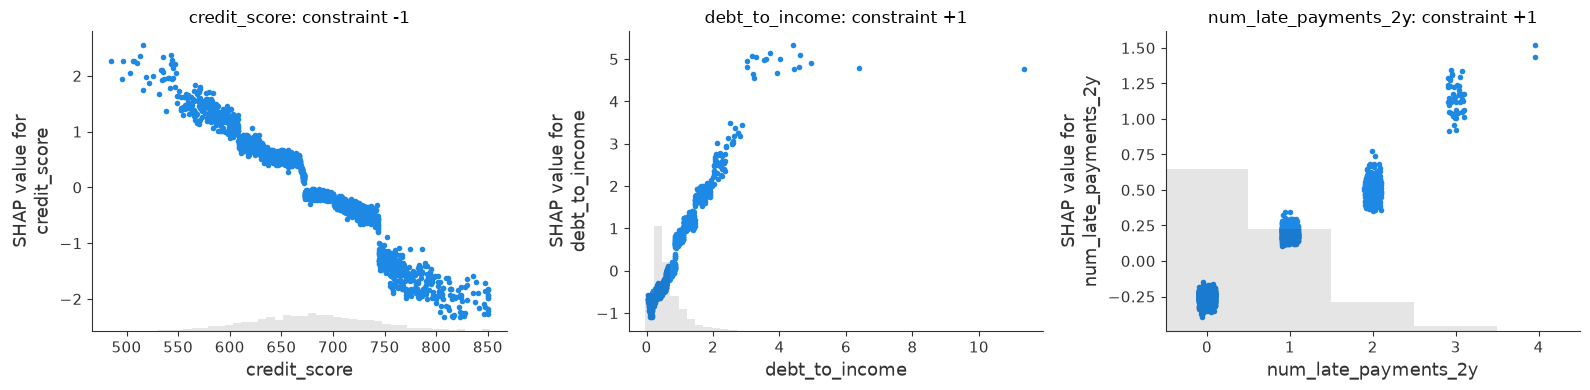

credit_score           monotonic -: PASS


num_late_payments_2y   monotonic +: PASS


debt_to_income         monotonic +: PASS


years_employed         monotonic -: PASS


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, ["credit_score", "debt_to_income", "num_late_payments_2y"]):
    shap.plots.scatter(shap_values[:, feature], ax=ax, show=False)
    ax.set_title(f"{feature}: constraint {MONOTONE[feature]:+d}")
plt.tight_layout(); plt.show()


def check_monotonic(feature: str, direction: int, grid_size: int = 30) -> bool:
    """Automated check: move one feature across its range for 200 applicants and verify the trend."""
    grid = np.linspace(X_test[feature].quantile(0.01), X_test[feature].quantile(0.99), grid_size)
    sample = X_test.sample(200, random_state=RANDOM_STATE)
    for _, row in sample.iterrows():
        batch = pd.DataFrame([row] * grid_size).assign(**{feature: grid})
        risk = model.predict_proba(batch)[:, 1]
        if np.any(np.diff(risk) * direction < -1e-9):
            return False
    return True


for feature, direction in MONOTONE.items():
    print(f"{feature:22s} monotonic {'+' if direction > 0 else '-'}: {'PASS' if check_monotonic(feature, direction) else 'FAIL'}")

---
## 6. Local explanations: why was *this* applicant declined?

The **waterfall plot** starts from the **base value** (average risk across all applicants) and adds each feature's contribution until it reaches this applicant's final score.
This is what a loan officer would look at when a customer calls to ask "why?".

Applicant #3076 | predicted default risk 18.7% -> DECLINED
annual_income           54000.000
loan_amount              7900.000
credit_score              697.000
years_employed              0.900
num_late_payments_2y        1.000
existing_debt           43800.000
home_owner                  1.000
debt_to_income              0.957


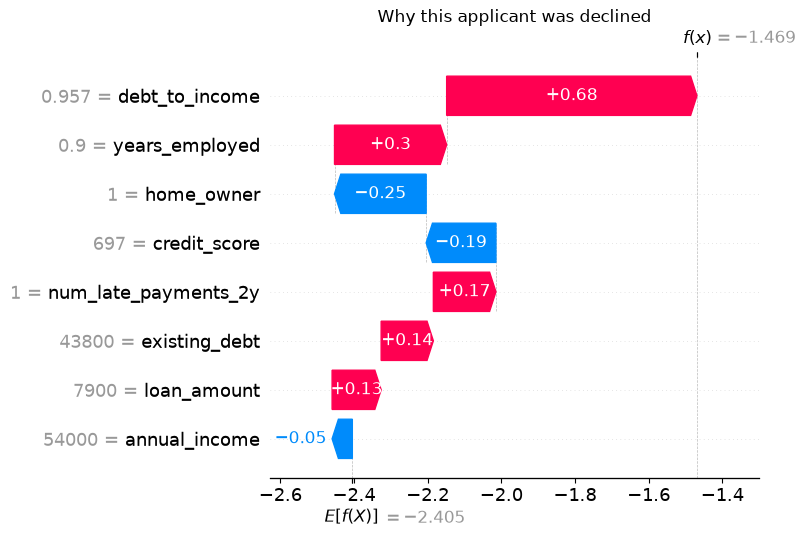

In [6]:
declined_positions = np.where(risk_test >= APPROVAL_THRESHOLD)[0]
applicant_pos = int(declined_positions[0])                       # first declined applicant in the test set

print(f"Applicant #{X_test.index[applicant_pos]} | predicted default risk {risk_test[applicant_pos]:.1%} -> DECLINED")
print(X_test.iloc[applicant_pos].to_string())

shap.plots.waterfall(shap_values[applicant_pos], max_display=9, show=False)
plt.title("Why this applicant was declined"); plt.tight_layout(); plt.show()

### Two things SHAP does NOT tell you
1. **SHAP explains the model, not the world.** "Debt-to-income pushed the risk up" means *the model* uses it that way. It does **not** prove that lowering someone's debt would cause them to repay. (SHAP docs: *"Be careful when interpreting predictive models in search of causal insights"*.)
2. **Correlated features share the credit.** `debt_to_income` is computed from `existing_debt` and `loan_amount`, so SHAP may split the "debt" story across all three, and small data changes can swap which one ranks first. Mature teams **group** related features (e.g. "debt burden") before writing reason codes.

---
## 7. Turning SHAP into customer reason codes

Customers don't read waterfall plots. Lenders send letters with **2-4 reasons in plain language**. This is called an **adverse action notice**.
We map each feature to a sentence and pick the features that increased risk the most, but **only** reasons the customer can understand and possibly act on.

In [7]:
REASON_TEXT = {
    "credit_score": "Credit score is lower than typical approved applicants",
    "debt_to_income": "Total debt is high relative to income",
    "num_late_payments_2y": "Recent history of late payments",
    "years_employed": "Short employment history",
    "existing_debt": "High existing debt balance",
    "loan_amount": "Requested loan amount is high",
    "annual_income": "Income is low relative to the requested loan",
    "home_owner": "No home ownership on record",
}


def reason_codes(position: int, top_n: int = 3) -> list[str]:
    """Top features that pushed THIS applicant's risk up, as customer-friendly text."""
    contributions = pd.Series(shap_values.values[position], index=FEATURES)
    risk_increasing = contributions[contributions > 0].sort_values(ascending=False)
    return [REASON_TEXT[f] for f in risk_increasing.index[:top_n]]


def decision_letter(position: int) -> str:
    risk = risk_test[position]
    if risk < APPROVAL_THRESHOLD:
        return "Decision: APPROVED"
    reasons = "\n".join(f"  {i}. {r}" for i, r in enumerate(reason_codes(position), start=1))
    return f"Decision: DECLINED\nPrincipal reasons:\n{reasons}"


for pos in declined_positions[:3]:
    print(f"--- Applicant #{X_test.index[pos]} (risk {risk_test[pos]:.1%}) ---")
    print(decision_letter(pos), "\n")

--- Applicant #3076 (risk 18.7%) ---
Decision: DECLINED
Principal reasons:
  1. Total debt is high relative to income
  2. Short employment history
  3. Recent history of late payments 

--- Applicant #4645 (risk 18.7%) ---
Decision: DECLINED
Principal reasons:
  1. Total debt is high relative to income
  2. Income is low relative to the requested loan
  3. High existing debt balance 

--- Applicant #7850 (risk 20.0%) ---
Decision: DECLINED
Principal reasons:
  1. Total debt is high relative to income
  2. Recent history of late payments
  3. Short employment history 



---
## 8. Fairness spot-check

Even without using `age_group` as input, a model can treat groups differently through **correlated** features (proxies).
A first check every regulated company runs: **approval rates per group**, summarised by the **adverse impact ratio (AIR)** = a group's approval rate ÷ the most-approved group's rate.

A common screening convention flags any group with **AIR below 0.8**. It comes from the US "four-fifths rule" in *employment* guidance (EEOC). In lending it is a widely used rule of thumb, **not a legal pass/fail test**. A flag means "investigate", and real audits add statistical significance tests and error-rate comparisons (e.g. with the `fairlearn` library).
For a full treatment, see `../../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb`.

In [8]:
fairness = pd.DataFrame({"approved": risk_test < APPROVAL_THRESHOLD, "age_group": age_test.values,
                         "defaulted": y_test.values})
by_group = fairness.groupby("age_group").agg(applicants=("approved", "size"),
                                             approval_rate=("approved", "mean"),
                                             actual_default_rate=("defaulted", "mean"))
by_group["adverse_impact_ratio"] = by_group["approval_rate"] / by_group["approval_rate"].max()
by_group["screening_flag"] = np.where(by_group["adverse_impact_ratio"] >= 0.8, "ok", "INVESTIGATE")
by_group.round(3)

,applicants,approval_rate,actual_default_rate,adverse_impact_ratio,screening_flag
age_group,,,,,
18-30,723,0.719,0.134,1.000,ok
31-50,1170,0.702,0.144,0.976,ok
51+,607,0.710,0.138,0.987,ok


---
## 9. Model card

A **model card** is a short document that travels with the model (Google introduced the format in 2019; it's now standard practice and often required by regulators). We generate one automatically from the facts computed above.

In [9]:
global_importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)

model_card = f"""
# Model Card: Loan Default Risk v1.0

## Intended use
Estimate probability of default for personal-loan applications. Applications with risk >= {APPROVAL_THRESHOLD:.0%}
are declined, or referred to a human underwriter. NOT for: mortgages, business loans.

## Training data
{len(X_train):,} historical applications (simulated for this tutorial). Default rate {y_train.mean():.1%}.
Protected attributes (age group) are NOT model inputs; used only for fairness auditing.

## Performance (held-out test set, {len(X_test):,} applications)
- ROC-AUC: {roc_auc_score(y_test, risk_test):.3f}
- Approval rate: {(risk_test < APPROVAL_THRESHOLD).mean():.1%}

## Most influential features (mean |SHAP|)
""" + "\n".join(f"- {f}: {v:.3f}" for f, v in global_importance.head(5).items()) + f"""

## Safeguards
- Monotonic constraints on: {', '.join(MONOTONE)} (verified automatically)
- Customer reason codes generated from SHAP for every decline
- Adverse impact ratio screen per age group (flag if < 0.8): {', '.join(f'{g}={r:.2f}' for g, r in by_group['adverse_impact_ratio'].items())}

## Limitations
- Trained on past approved applicants only (selection bias / "reject inference" not addressed).
- Must be re-validated if economic conditions change significantly (monitor drift monthly).
"""
print(model_card)


# Model Card: Loan Default Risk v1.0

## Intended use
Estimate probability of default for personal-loan applications. Applications with risk >= 15%
are declined, or referred to a human underwriter. NOT for: mortgages, business loans.

## Training data
7,500 historical applications (simulated for this tutorial). Default rate 14.0%.
Protected attributes (age group) are NOT model inputs; used only for fairness auditing.

## Performance (held-out test set, 2,500 applications)
- ROC-AUC: 0.790
- Approval rate: 70.9%

## Most influential features (mean |SHAP|)
- credit_score: 0.692
- debt_to_income: 0.618
- num_late_payments_2y: 0.275
- years_employed: 0.222
- annual_income: 0.161

## Safeguards
- Monotonic constraints on: credit_score, num_late_payments_2y, debt_to_income, years_employed (verified automatically)
- Customer reason codes generated from SHAP for every decline
- Adverse impact ratio screen per age group (flag if < 0.8): 18-30=1.00, 31-50=0.98, 51+=0.99

## Limitations
- Traine

---
## 10. Summary

| Need | Industry answer used here |
|---|---|
| Accurate model that respects business logic | LightGBM + **monotonic constraints** |
| "What drives the model?" (managers, risk team) | SHAP bar + beeswarm |
| "Is the behaviour sensible?" | Dependence plots + **automated monotonicity test** |
| "Why was I declined?" (customer) | SHAP waterfall → **reason codes** → decision letter |
| "Is it fair?" (regulator) | Approval rate by group, adverse impact ratio screen |
| "What is this model?" (everyone) | Auto-generated **model card** |

### Practice exercises
1. Remove the monotonic constraints and re-run Section 5. Do any checks fail?
2. Change `APPROVAL_THRESHOLD` to 10%. How do the adverse impact ratios per age group change?
4. Group `existing_debt`, `loan_amount` and `debt_to_income` into one reason "Debt burden" by summing their SHAP values before ranking.
3. Exclude `home_owner` from reason codes (it may feel unfair to customers) and show the next-best reason instead.

### Resources
- SHAP documentation and example notebooks: https://shap.readthedocs.io
- Mitchell et al. (2019), *Model Cards for Model Reporting*: https://arxiv.org/abs/1810.03993
- LightGBM monotonic constraints: https://lightgbm.readthedocs.io/en/latest/Parameters.html#monotone_constraints

### Related notebooks
- Theory of SHAP/LIME/PDP: `01_explainability.ipynb`
- Glass-box models and monotonic constraints: `02_interpretable_models.ipynb`
- Fairness in depth: `../../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb`